###  Exercise: Predicting Customer Churn with Logistic Regression

### Business Problem Context
You are a Lead Data Scientist at a major telecom provider. Customer retention is critical: acquiring a new customer costs 5x more than retaining an existing one. 

Your goal is to build a **Logistic Regression model** to predict whether a customer will churn (`1 = Churned`, `0 = Retained`), interpret feature coefficients to identify churn drivers, and evaluate performance using appropriate metrics beyond raw accuracy.

---

###  Key Learning Objectives
1. **Prepare Features**: Encode categorical features and scale numerical variables to ensure balanced gradient updates.
2. **Train Logistic Regression**: Fit a model using Scikit-Learn.
3. **Interpret Odds Ratios**: Convert log-odds coefficients ($\beta$) into **Odds Ratios** ($e^\beta$) to quantify feature impact.
4. **Evaluate Model**: Calculate Confusion Matrix, Precision, Recall, F1-Score, and ROC-AUC.

In [1]:
# =====================================================================
# Setup & Package Imports
# =====================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    roc_auc_score, 
    confusion_matrix, 
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# Seed for reproducibility
SEED = 2026

---
## Step 1: Generate & Inspect Synthetic Customer Churn Dataset

In [2]:
# =====================================================================
# Generate Synthetic Telecom Churn Data
# =====================================================================
np.random.seed(SEED)
n_samples = 1000

data = {
    "tenure_months": np.random.randint(1, 72, size=n_samples),
    "monthly_charges": np.random.uniform(20.0, 120.0, size=n_samples),
    "total_charges": None, # Will be computed below
    "contract_type": np.random.choice(["Month-to-Month", "One-Year", "Two-Year"], size=n_samples, p=[0.5, 0.3, 0.2]),
    "tech_support": np.random.choice([0, 1], size=n_samples, p=[0.6, 0.4]),
}

df = pd.DataFrame(data)
df["total_charges"] = df["tenure_months"] * df["monthly_charges"] + np.random.normal(0, 50, size=n_samples)
df["total_charges"] = df["total_charges"].clip(lower=20.0)

# Simulate churn outcome with probabilistic logit formula
logit = (
    1.2 
    - 0.05 * df["tenure_months"] 
    + 0.03 * df["monthly_charges"] 
    - 1.5 * (df["contract_type"] == "Two-Year") 
    - 0.8 * df["tech_support"]
)
prob_churn = 1 / (1 + np.exp(-logit))
df["churn"] = (prob_churn > np.random.uniform(0, 1, size=n_samples)).astype(int)

print(f"Dataset Shape: {df.shape}")
print("\nClass Distribution:")
print(df["churn"].value_counts(normalize=True).map("{:.2%}".format))
df.head()

Dataset Shape: (1000, 6)

Class Distribution:
churn
1    60.90%
0    39.10%
Name: proportion, dtype: str


,tenure_months,monthly_charges,total_charges,contract_type,tech_support,churn
0,2,54.166478,86.852227,Month-to-Month,0,1
1,7,116.245892,894.825166,Month-to-Month,0,1
2,27,117.392977,3016.803006,Two-Year,1,1
3,57,110.129535,6229.626084,Month-to-Month,0,1
4,30,100.991742,3005.493801,Month-to-Month,1,1


---
## Step 2: Preprocessing & Feature Engineering

In [3]:
# =====================================================================
# TODO 1: Feature Preprocessing
# 1. One-hot encode 'contract_type' using pd.get_dummies(..., drop_first=True)
# 2. Split data into X (features) and y (target 'churn')
# 3. Perform 80/20 train/test split with stratify=y and random_state=SEED
# =====================================================================

# --- YOUR CODE HERE ---
df_encoded = pd.get_dummies(df, columns=["contract_type"], drop_first=True)
X = df_encoded.drop(columns=["churn"])
y = df_encoded["churn"]
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=SEED)

# Un-comment and complete below:
# df_encoded = pd.get_dummies(df, columns=["contract_type"], drop_first=True)
# X = df_encoded.drop(columns=["churn"])
# y = df_encoded["churn"]
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)


# --- CHECK YOUR IMPLEMENTATION ---
assert X_train.shape[0] == 800, "X_train should have 800 rows"
assert X_test.shape[0] == 200, "X_test should have 200 rows"
print("✅ Task 1 Completed Successfully!")

✅ Task 1 Completed Successfully!


In [7]:
# =====================================================================
# TODO 2: Feature Scaling
# Scale continuous numerical features: ['tenure_months', 'monthly_charges', 'total_charges']
# Fit scaler ONLY on X_train, then transform X_train and X_test.
# =====================================================================

num_cols = ["tenure_months", "monthly_charges", "total_charges"]

X_train[num_cols] = X_train[num_cols].astype(float)
X_test[num_cols] = X_test[num_cols].astype(float)

# --- YOUR CODE HERE ---
scaler = StandardScaler()

X_train.loc[:, num_cols] = scaler.fit_transform(X_train[num_cols])
X_test.loc[:, num_cols] = scaler.transform(X_test[num_cols])


# --- CHECK YOUR IMPLEMENTATION ---
assert np.isclose(X_train["tenure_months"].mean(), 0, atol=1e-2), "Numerical features must be standard scaled"
print("✅ Task 2 Completed Successfully!")

✅ Task 2 Completed Successfully!


---
## Step 3: Model Training & Coefficient Interpretation

In [8]:
# =====================================================================
# TODO 3: Train Logistic Regression & Extract Odds Ratios
# 1. Instantiate LogisticRegression with random_state=SEED
# 2. Fit model on (X_train, y_train)
# 3. Create a DataFrame containing Feature Names, Coefficients (beta), and Odds Ratios (np.exp(beta))
# =====================================================================

# --- YOUR CODE HERE ---
model = LogisticRegression()
model.fit(X_train, y_train)

coef_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient_Beta": model.coef_[0],
    "Odds_Ratio": np.exp(model.coef_[0])
}).sort_values(by="Odds_Ratio", ascending=False)


# --- CHECK YOUR IMPLEMENTATION ---
assert hasattr(model, "coef_"), "Model must be trained"
print("✅ Task 3 Completed Successfully!")
# coef_df

✅ Task 3 Completed Successfully!


---
## Step 4: Model Evaluation

In [9]:
# =====================================================================
# TODO 4: Calculate Classification Metrics on Test Set
# Calculate Accuracy, Precision, Recall, F1-Score, and ROC-AUC Score.
# =====================================================================

# --- YOUR CODE HERE ---
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1-Score": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_proba)
}

for metric_name, val in metrics.items():
    print(f"{metric_name:12s}: {val:.4f}")

Accuracy    : 0.6900
Precision   : 0.7090
Recall      : 0.8051
F1-Score    : 0.7540
ROC-AUC     : 0.7897


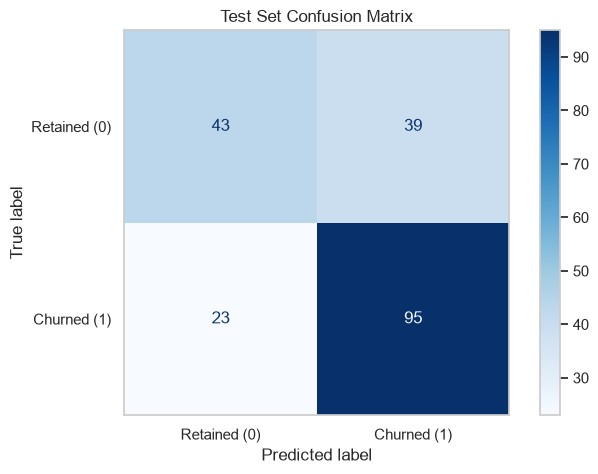

In [10]:
# =====================================================================
# Visualize Confusion Matrix
# =====================================================================
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Retained (0)", "Churned (1)"]).plot(cmap="Blues")
plt.grid(False)
plt.title("Test Set Confusion Matrix")
plt.show()

---
## 📌 Summary & Reflection
1. **Odds Ratios ($e^\beta$)**:
   * An **Odds Ratio > 1.0** indicates that as the feature increases, the likelihood of churn **increases**.
   * An **Odds Ratio < 1.0** indicates a protective factor—as the feature increases, churn likelihood **decreases**.
2. **Business Application**:
   * In churn prediction, **Recall** is often prioritized over Precision. Missing a churned customer (False Negative) costs significant lost revenue, whereas offering a promo to a loyal customer (False Positive) carries low marginal cost.